# CW1: Cloud AI Framework for Credit Card Fraud Detection
## Notebook 1: Exploratory Data Analysis and Preprocessing

**Module:** COS7054-B Cloud AI  
**Dataset:** ULB Credit Card Fraud Detection (Kaggle, `mlg-ulb/creditcardfraud`)

This notebook covers the data preparation stage of the AI lifecycle: data ingestion, analysis, cleaning, transformation, validation and creation of training data.

---

### 1. Environment Setup

This step imports the libraries used throughout the notebook, fixes the random seed so results are reproducible, and creates a `figures` folder where every chart is saved for the report.

In [1]:
# Core libraries
import os
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

# Reproducibility: fixed seed used in every random step
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Paths
DATA_PATH = os.path.join("data", "creditcard.csv")
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

# Consistent, report-ready chart style
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["savefig.bbox"] = "tight"
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:.4f}".format)

# Record versions for reproducibility (useful in the report appendix)
print(f"Python:       {sys.version.split()[0]}")
print(f"pandas:       {pd.__version__}")
print(f"numpy:        {np.__version__}")
print(f"matplotlib:   {matplotlib.__version__}")
print(f"seaborn:      {sns.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"\nDataset found: {os.path.exists(DATA_PATH)}  ->  {os.path.abspath(DATA_PATH)}")

Python:       3.13.5
pandas:       2.2.3
numpy:        2.1.3
matplotlib:   3.10.0
seaborn:      0.13.2
scikit-learn: 1.6.1

Dataset found: True  ->  C:\Users\User\OneDrive\Desktop\Clients Projects\Cloud AI Fraud Detection\data\creditcard.csv


### 2. Data Ingestion

This step loads the transaction data into a pandas DataFrame and inspects its basic structure: the number of rows and columns, the data types, memory usage and the first few records. This confirms the data was read correctly before any analysis.

In [2]:
# Load the dataset
df = pd.read_csv(DATA_PATH)

# Basic structure
print(f"Rows (transactions): {df.shape[0]:,}")
print(f"Columns (features):  {df.shape[1]}")
print(f"Memory usage:        {df.memory_usage(deep=True).sum() / 1024**2:.1f} MB")

# Column names grouped by meaning
pca_cols = [c for c in df.columns if c.startswith("V")]
print(f"\nPCA-transformed features: {len(pca_cols)} ({pca_cols[0]} to {pca_cols[-1]})")
print("Non-anonymised features:  Time, Amount")
print("Target variable:          Class (0 = legitimate, 1 = fraud)")

# Data types summary
print("\nData types:")
print(df.dtypes.value_counts().to_string())

# First five transactions
df.head()

Rows (transactions): 284,807
Columns (features):  31
Memory usage:        67.4 MB

PCA-transformed features: 28 (V1 to V28)
Non-anonymised features:  Time, Amount
Target variable:          Class (0 = legitimate, 1 = fraud)

Data types:
float64    30
int64       1


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0000,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,0.0908,-0.5516,-0.6178,-0.9914,-0.3112,1.4682,-0.4704,0.2080,0.0258,0.4040,0.2514,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,0.0000,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,-0.1670,1.6127,1.0652,0.4891,-0.1438,0.6356,0.4639,-0.1148,-0.1834,-0.1458,-0.0691,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,1.0000,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,0.2076,0.6245,0.0661,0.7173,-0.1659,2.3459,-2.8901,1.1100,-0.1214,-2.2619,0.5250,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0
3,1.0000,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,-0.0550,-0.2265,0.1782,0.5078,-0.2879,-0.6314,-1.0596,-0.6841,1.9658,-1.2326,-0.2080,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.5000,0
4,2.0000,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,0.7531,-0.8228,0.5382,1.3459,-1.1197,0.1751,-0.4514,-0.2370,-0.0382,0.8035,0.4085,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.9900,0


### 3. Data Validation and Cleaning

This step checks data quality before analysis. It looks for missing values, duplicate transactions and invalid entries (such as zero-value amounts), then removes exact duplicates. Duplicates can leak identical records into both the training and test sets, which would inflate model performance, so they are removed before any splitting.

In [3]:
# 1. Missing values
missing = df.isna().sum().sum()
print(f"Missing values (total): {missing}")

# 2. Duplicate transactions (exact copies of an earlier row)
dupes = df[df.duplicated(keep="first")]
print(f"\nDuplicate rows:         {len(dupes):,}")
print(f"  of which legitimate:  {(dupes['Class'] == 0).sum():,}")
print(f"  of which fraud:       {(dupes['Class'] == 1).sum():,}")

# 3. Invalid or unusual values
print(f"\nZero-amount transactions: {(df['Amount'] == 0).sum():,}")
print(f"Negative amounts:         {(df['Amount'] < 0).sum():,}")
print(f"Time span covered:        {df['Time'].max() / 3600:.1f} hours (~2 days)")

# 4. Remove duplicates, keeping the first occurrence
rows_before = len(df)
df = df.drop_duplicates(keep="first").reset_index(drop=True)
print(f"\nRows before cleaning: {rows_before:,}")
print(f"Rows after cleaning:  {len(df):,}  (removed {rows_before - len(df):,})")
print(f"Fraud cases remaining: {df['Class'].sum():,}")

# 5. Summary statistics for the two non-anonymised features
df[["Time", "Amount"]].describe()

Missing values (total): 0

Duplicate rows:         1,081
  of which legitimate:  1,062
  of which fraud:       19

Zero-amount transactions: 1,825
Negative amounts:         0
Time span covered:        48.0 hours (~2 days)

Rows before cleaning: 284,807
Rows after cleaning:  283,726  (removed 1,081)
Fraud cases remaining: 473


,Time,Amount
count,283726.0000,283726.0000
mean,94811.0776,88.4727
std,47481.0479,250.3994
min,0.0000,0.0000
25%,54204.7500,5.6000
50%,84692.5000,22.0000
75%,139298.0000,77.5100
max,172792.0000,25691.1600


### 4. Class Distribution

This step measures how imbalanced the target variable is. It counts legitimate and fraudulent transactions, calculates the fraud rate and imbalance ratio, and plots both on a linear and a logarithmic scale. On a linear scale the fraud class is almost invisible, which shows why accuracy is a misleading metric for this problem.

Legitimate transactions: 283,253
Fraudulent transactions: 473
Fraud rate:              0.1667%
Imbalance ratio:         1 fraud per 599 legitimate

A model predicting 'legitimate' for everything would score 99.83% accuracy while catching zero fraud.


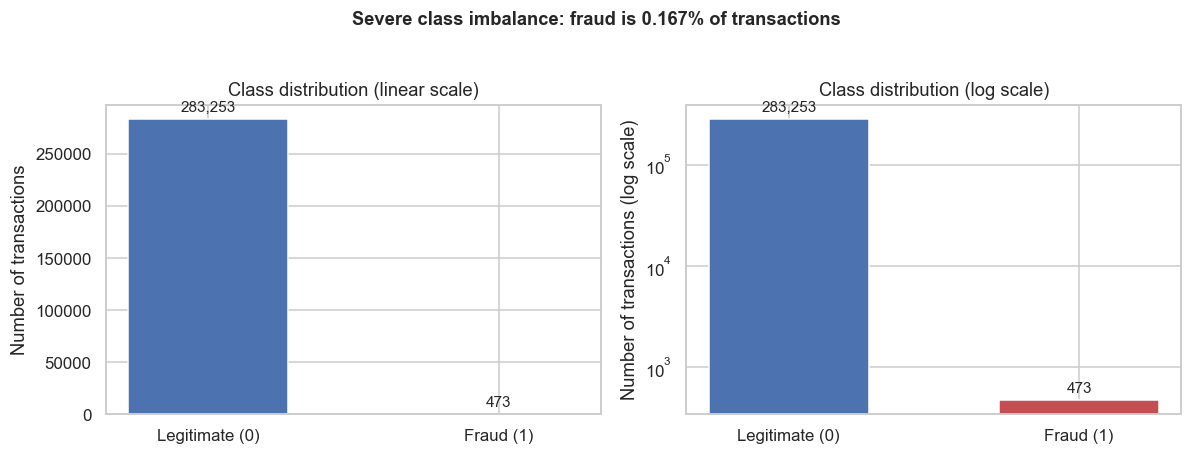

In [4]:
# Counts and proportions
counts = df["Class"].value_counts().sort_index()
legit, fraud = counts[0], counts[1]
fraud_rate = fraud / len(df) * 100

print(f"Legitimate transactions: {legit:,}")
print(f"Fraudulent transactions: {fraud:,}")
print(f"Fraud rate:              {fraud_rate:.4f}%")
print(f"Imbalance ratio:         1 fraud per {legit / fraud:,.0f} legitimate")
print(f"\nA model predicting 'legitimate' for everything would score "
      f"{legit / len(df) * 100:.2f}% accuracy while catching zero fraud.")

# Plot: linear vs log scale side by side
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
labels = ["Legitimate (0)", "Fraud (1)"]
colors = ["#4C72B0", "#C44E52"]

for ax, scale in zip(axes, ["linear", "log"]):
    bars = ax.bar(labels, [legit, fraud], color=colors, width=0.55)
    ax.set_yscale(scale)
    ax.set_ylabel("Number of transactions" + (" (log scale)" if scale == "log" else ""))
    ax.set_title(f"Class distribution ({scale} scale)")
    for bar, value in zip(bars, [legit, fraud]):
        ax.annotate(f"{value:,}", (bar.get_x() + bar.get_width() / 2, value),
                    ha="center", va="bottom", fontsize=10, xytext=(0, 3),
                    textcoords="offset points")

plt.suptitle(f"Severe class imbalance: fraud is {fraud_rate:.3f}% of transactions",
             fontsize=12, fontweight="bold", y=1.03)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig1_class_distribution.png"))
plt.show()

### 5. Transaction Amount and Time Analysis

This step compares how transaction amount and time of day differ between legitimate and fraudulent transactions. `Time` records seconds since the first transaction, so it is converted into an hour of the day (0–23). These are the only two features with real-world meaning, so they show whether fraud has recognisable spending or timing patterns.

Transaction amount by class:
               mean    25%     50%      75%        max
Class                                                 
Legitimate  88.4136 5.6700 22.0000  77.4600 25691.1600
Fraud      123.8719 1.0000  9.8200 105.8900  2125.8700

Fraud rate 00:00-06:00: 0.482%
Fraud rate 06:00-24:00: 0.138%  ->  night rate is 3.5x higher


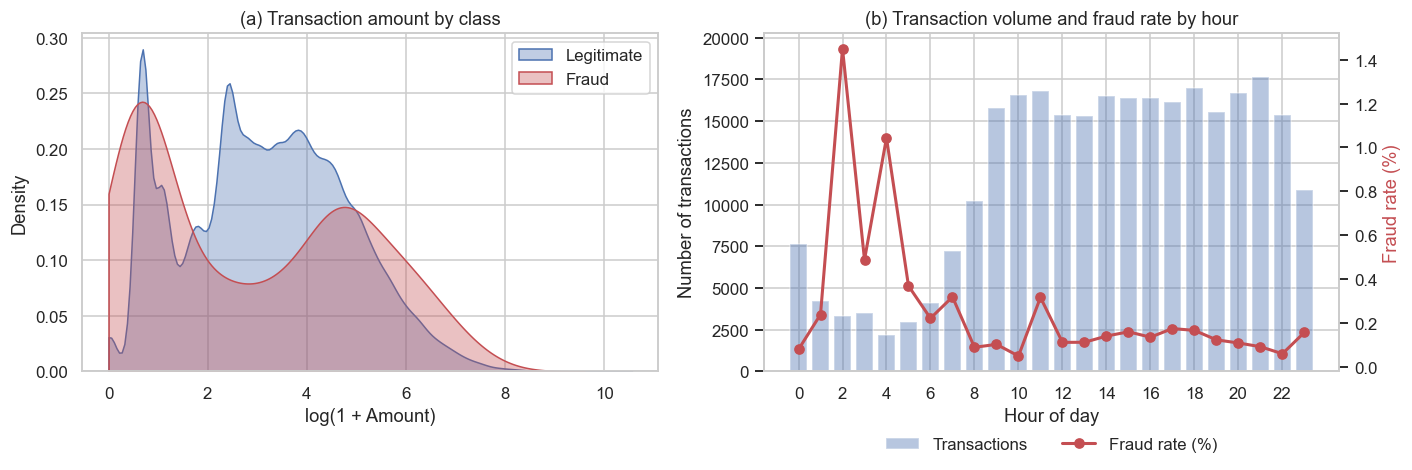

In [8]:
# Hour of day derived from Time (dataset covers two days)
df["Hour"] = (df["Time"] // 3600) % 24

# Amount statistics by class
print("Transaction amount by class:")
print(df.groupby("Class")["Amount"].describe()[["mean", "25%", "50%", "75%", "max"]]
        .rename(index={0: "Legitimate", 1: "Fraud"}))

# Fraud rate by hour
hourly = df.groupby("Hour").agg(transactions=("Class", "size"), frauds=("Class", "sum"))
hourly["fraud_rate_%"] = hourly["frauds"] / hourly["transactions"] * 100
night = df[df["Hour"] < 6]["Class"].mean() * 100
day = df[df["Hour"] >= 6]["Class"].mean() * 100
print(f"\nFraud rate 00:00-06:00: {night:.3f}%")
print(f"Fraud rate 06:00-24:00: {day:.3f}%  ->  night rate is {night / day:.1f}x higher")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# (a) Amount distribution by class, log scale to handle the skew
for cls, color, label in [(0, "#4C72B0", "Legitimate"), (1, "#C44E52", "Fraud")]: 
    sns.kdeplot(np.log1p(df.loc[df["Class"] == cls, "Amount"]), ax=axes[0],
            fill=True, alpha=0.35, color=color, label=label,
            common_norm=False, clip=(0, None))
axes[0].set_xlabel("log(1 + Amount)")
axes[0].set_ylabel("Density")
axes[0].set_title("(a) Transaction amount by class")
axes[0].legend()

# (b) Volume and fraud rate by hour
ax_b = axes[1]
ax_b.bar(hourly.index, hourly["transactions"], color="#4C72B0", alpha=0.4,
         label="Transactions")
ax_b.set_xlabel("Hour of day")
ax_b.set_ylabel("Number of transactions")
ax_b.set_ylim(0, hourly["transactions"].max() * 1.15)   # headroom for labels
ax_b.set_xticks(range(0, 24, 2))
ax_r = ax_b.twinx()
ax_r.plot(hourly.index, hourly["fraud_rate_%"], color="#C44E52", marker="o",
          linewidth=2, label="Fraud rate (%)")
ax_r.set_ylabel("Fraud rate (%)", color="#C44E52")
ax_r.grid(False)
ax_b.set_title("(b) Transaction volume and fraud rate by hour")
lines = ax_b.get_legend_handles_labels()[0] + ax_r.get_legend_handles_labels()[0]
ax_b.legend(lines, ["Transactions", "Fraud rate (%)"], loc="upper center",
            bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig2_amount_time_patterns.png"))
plt.show()

### 6. Feature Correlation Analysis

This step measures how strongly each feature is linked to fraud using Pearson correlation with the `Class` label. It also checks correlation between the PCA features themselves. PCA components are designed to be uncorrelated, so low inter-feature correlation confirms the transformation and means multicollinearity is not a concern. The most fraud-correlated features are then compared across classes with box plots.

Six features most correlated with fraud:
V17   -0.3130
V14   -0.2930
V12   -0.2510
V10   -0.2070
V16   -0.1870
V3    -0.1820

Maximum correlation between any two PCA features: 0.0189


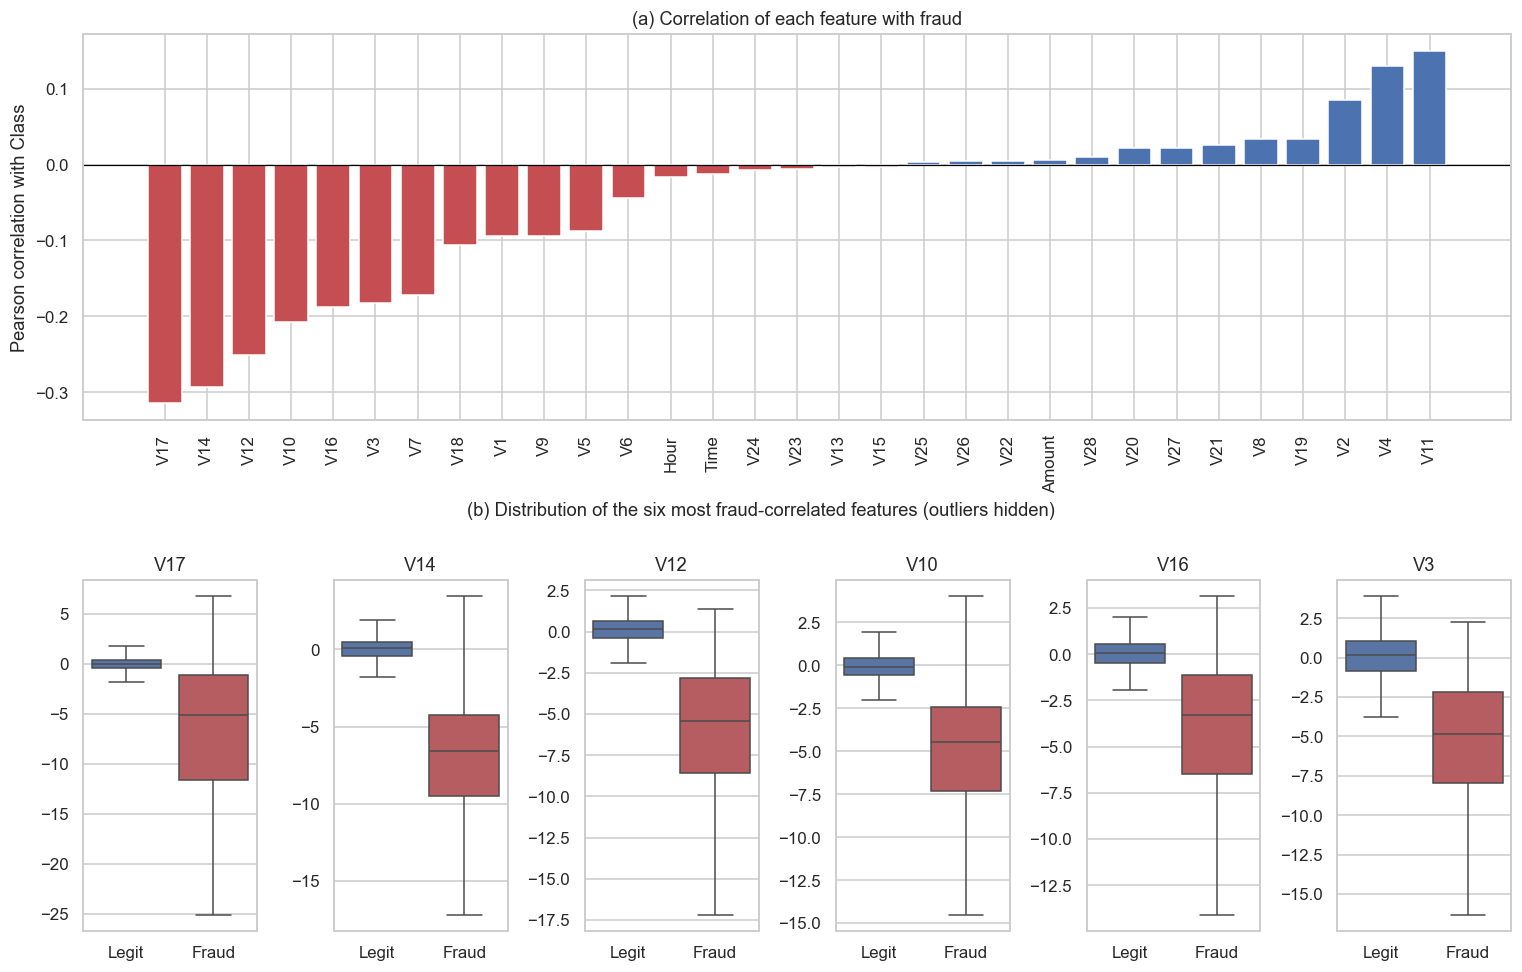

In [7]:
features = df.drop(columns="Class")

# 1. Correlation of every feature with the fraud label
corr_with_class = features.corrwith(df["Class"]).sort_values()
top_features = corr_with_class.abs().sort_values(ascending=False).head(6).index.tolist()
print("Six features most correlated with fraud:")
print(corr_with_class[top_features].round(3).to_string())

# 2. Correlation among the PCA features (should be close to zero)
pca_corr = df[pca_cols].corr().abs().to_numpy().copy()
np.fill_diagonal(pca_corr, 0)
print(f"\nMaximum correlation between any two PCA features: {pca_corr.max():.4f}")

fig = plt.figure(figsize=(14, 9))
grid = fig.add_gridspec(2, 6, height_ratios=[1.1, 1])

# (a) Correlation with Class, all features
ax_a = fig.add_subplot(grid[0, :])
bar_colors = ["#C44E52" if v < 0 else "#4C72B0" for v in corr_with_class]
ax_a.bar(corr_with_class.index, corr_with_class.values, color=bar_colors)
ax_a.axhline(0, color="black", linewidth=0.8)
ax_a.set_ylabel("Pearson correlation with Class")
ax_a.set_title("(a) Correlation of each feature with fraud")
ax_a.tick_params(axis="x", rotation=90)

# (b) Box plots of the six strongest features, split by class
for i, feat in enumerate(top_features):
    ax = fig.add_subplot(grid[1, i])
    sns.boxplot(data=df, x="Class", y=feat, hue="Class", ax=ax, legend=False,
                palette={0: "#4C72B0", 1: "#C44E52"}, showfliers=False)
    ax.set_title(feat)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Legit", "Fraud"])
fig.text(0.5, 0.47, "(b) Distribution of the six most fraud-correlated features (outliers hidden)",
         ha="center", fontsize=12)

plt.tight_layout(h_pad=3.5)
plt.savefig(os.path.join(FIG_DIR, "fig3_feature_correlation.png"))
plt.show()

### 7. Clustering Analysis

This step tests whether fraud forms natural groups without using the labels. A stratified sample (all 473 frauds plus 5,000 random legitimate transactions) is standardised, then clustered with k-means for k = 2 to 4, and each cluster's fraud content is checked. t-SNE then projects the 29 features into two dimensions for visual inspection. If fraud separates cleanly, unsupervised methods could detect it; if it overlaps with legitimate transactions, supervised learning is needed.

Sample size: 5,473 (473 fraud)

k = 2:  silhouette = 0.668,  fraud isolated in fraud-only clusters = 191/473 (40%)
k = 3:  silhouette = 0.450,  fraud isolated in fraud-only clusters = 364/473 (77%)
k = 4:  silhouette = 0.069,  fraud isolated in fraud-only clusters = 364/473 (77%)

Cluster composition for k = 3:
Class       0    1
Cluster           
0           0  266
1        5000  109
2           0   98


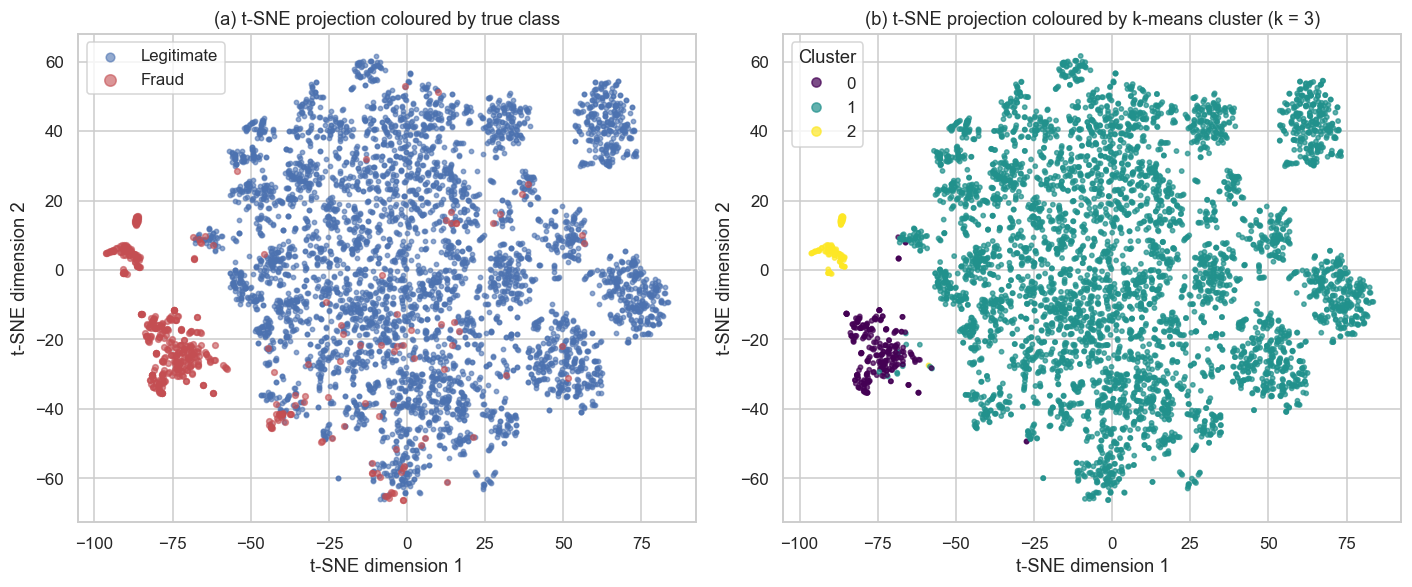

In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

# Stratified sample: all frauds + 5,000 legitimate (t-SNE is too slow for 283k rows)
sample = pd.concat([
    df[df["Class"] == 1],
    df[df["Class"] == 0].sample(5000, random_state=RANDOM_STATE)
]).reset_index(drop=True)

X_clu = sample[pca_cols].copy()
X_clu["logAmount"] = np.log1p(sample["Amount"])
X_clu = StandardScaler().fit_transform(X_clu)

# k-means for k = 2, 3, 4: silhouette score and fraud captured in pure-fraud clusters
print(f"Sample size: {len(sample):,} ({sample['Class'].sum()} fraud)\n")
results = {}
for k in [2, 3, 4]:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_clu)
    table = pd.crosstab(km.labels_, sample["Class"]).reindex(columns=[0, 1], fill_value=0)
    pure_fraud = table.loc[table[0] == 0, 1].sum()
    results[k] = km.labels_
    print(f"k = {k}:  silhouette = {silhouette_score(X_clu, km.labels_):.3f},  "
          f"fraud isolated in fraud-only clusters = {pure_fraud}/{sample['Class'].sum()} "
          f"({pure_fraud / sample['Class'].sum() * 100:.0f}%)")

K_CHOSEN = 3
print(f"\nCluster composition for k = {K_CHOSEN}:")
print(pd.crosstab(results[K_CHOSEN], sample["Class"], rownames=["Cluster"],
                  colnames=["Class"]))

# t-SNE projection to 2D (takes about 30-60 seconds)
emb = TSNE(n_components=2, perplexity=30, init="pca",
           random_state=RANDOM_STATE).fit_transform(X_clu)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

# (a) Coloured by true class
for cls, color, label, size in [(0, "#4C72B0", "Legitimate", 8), (1, "#C44E52", "Fraud", 14)]:
    m = sample["Class"] == cls
    axes[0].scatter(emb[m, 0], emb[m, 1], s=size, c=color, alpha=0.6, label=label)
axes[0].set_title("(a) t-SNE projection coloured by true class")
axes[0].legend(markerscale=2)

# (b) Coloured by k-means cluster
sc = axes[1].scatter(emb[:, 0], emb[:, 1], c=results[K_CHOSEN], cmap="viridis",
                     s=8, alpha=0.7)
axes[1].set_title(f"(b) t-SNE projection coloured by k-means cluster (k = {K_CHOSEN})")
axes[1].legend(*sc.legend_elements(), title="Cluster", loc="best")

for ax in axes:
    ax.set_xlabel("t-SNE dimension 1")
    ax.set_ylabel("t-SNE dimension 2")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig4_clustering.png"))
plt.show()

### 8. Feature Engineering and Preprocessing Pipeline

This step turns the cleaned data into model-ready training and test sets:

1. **Feature engineering:** `Amount` is log-transformed to reduce its heavy right skew. `Hour` is encoded as sine and cosine values, so the model treats 23:00 and 00:00 as neighbours and can learn the overnight fraud pattern. Raw `Time` is dropped because it only counts seconds from the start of data collection and would not generalise to new transactions.
2. **Stratified train/test split (80/20):** the split preserves the 0.17% fraud rate in both sets. The test set is held back untouched until final evaluation.
3. **Scaling:** `log_Amount` is standardised. The scaler is fitted on the training set only, to avoid leaking test information into training.
4. **Saving artefacts:** the processed datasets and the fitted scaler are saved, so the modelling notebook and the Azure endpoint apply exactly the same transformation.

Resampling (SMOTE) is deliberately not applied here. It is applied only to training folds during modelling, so the test set keeps the real-world class balance.

In [10]:
from sklearn.model_selection import train_test_split
import joblib

# 1. Feature engineering
data = df.copy()
data["log_Amount"] = np.log1p(data["Amount"])
data["Hour_sin"] = np.sin(2 * np.pi * data["Hour"] / 24)
data["Hour_cos"] = np.cos(2 * np.pi * data["Hour"] / 24)
data = data.drop(columns=["Time", "Amount", "Hour"])

FEATURES = pca_cols + ["log_Amount", "Hour_sin", "Hour_cos"]
X = data[FEATURES]
y = data["Class"]
print(f"Final feature set: {len(FEATURES)} features")
print(f"  {len(pca_cols)} PCA components + log_Amount + Hour_sin + Hour_cos")

# 2. Stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print(f"\nTraining set: {len(X_train):,} rows, {y_train.sum()} fraud ({y_train.mean()*100:.4f}%)")
print(f"Test set:     {len(X_test):,} rows, {y_test.sum()} fraud ({y_test.mean()*100:.4f}%)")

# 3. Scale log_Amount using statistics from the training set only
scaler = StandardScaler()
X_train = X_train.copy()
X_test = X_test.copy()
X_train[["log_Amount"]] = scaler.fit_transform(X_train[["log_Amount"]])
X_test[["log_Amount"]] = scaler.transform(X_test[["log_Amount"]])
print(f"\nScaled log_Amount (train): mean = {X_train['log_Amount'].mean():.3f}, "
      f"std = {X_train['log_Amount'].std():.3f}")

# 4. Save artefacts for the modelling notebook and the cloud endpoint
os.makedirs(os.path.join("data", "processed"), exist_ok=True)
os.makedirs("models", exist_ok=True)
pd.concat([X_train, y_train], axis=1).to_csv(os.path.join("data", "processed", "train.csv"), index=False)
pd.concat([X_test, y_test], axis=1).to_csv(os.path.join("data", "processed", "test.csv"), index=False)
joblib.dump(scaler, os.path.join("models", "amount_scaler.joblib"))

print("\nSaved:")
for path in ["data/processed/train.csv", "data/processed/test.csv", "models/amount_scaler.joblib"]:
    print(f"  {path}  ({os.path.getsize(path) / 1024**2:.1f} MB)")

# 5. Final validation checks
assert X_train.isna().sum().sum() == 0 and X_test.isna().sum().sum() == 0
assert set(X_train.index).isdisjoint(set(X_test.index)), "Train/test overlap detected"
print("\nValidation passed: no missing values and no overlap between train and test.")

Final feature set: 31 features
  28 PCA components + log_Amount + Hour_sin + Hour_cos

Training set: 226,980 rows, 378 fraud (0.1665%)
Test set:     56,746 rows, 95 fraud (0.1674%)

Scaled log_Amount (train): mean = 0.000, std = 1.000

Saved:
  data/processed/train.csv  (124.1 MB)
  data/processed/test.csv  (31.0 MB)
  models/amount_scaler.joblib  (0.0 MB)

Validation passed: no missing values and no overlap between train and test.
